In [1]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "data" / "raw").is_dir():
            return folder
    raise FileNotFoundError("data/raw/ not found above " + str(start))

ROOT = find_project_root()
PROC_DIR = ROOT / "data" / "processed"

with open(PROC_DIR / "preprocessing_config.json") as f:
    config = json.load(f)

feature_sensors = config["feature_sensors"]
train = pd.read_csv(PROC_DIR / "train_with_rul.csv")
print(train.shape)
print(train.columns.tolist())

(20631, 17)
['unit', 'cycle', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21', 'RUL']


In [2]:
def add_rolling_features(df, sensors, window=10):
    """Trailing rolling mean and std, computed separately for each engine."""
    df = df.sort_values(["unit", "cycle"]).copy()
    g = df.groupby("unit")[sensors]

    roll_mean = g.rolling(window, min_periods=1).mean().reset_index(level=0, drop=True)
    roll_std = g.rolling(window, min_periods=2).std().reset_index(level=0, drop=True)

    roll_mean = roll_mean.add_suffix(f"_mean{window}")
    roll_std = roll_std.add_suffix(f"_std{window}")
    return df.join(roll_mean).join(roll_std)

feats = add_rolling_features(train, feature_sensors, window=10)
print(feats.shape)

std_cols = [c for c in feats.columns if c.endswith("_std10")]
print("NaNs in std columns before any fill:", int(feats[std_cols].isna().sum().sum()))
print("NaNs per std column:", int(feats[std_cols[0]].isna().sum()))

(20631, 45)
NaNs in std columns before any fill: 1400
NaNs per std column: 100


In [3]:
full = add_rolling_features(train, feature_sensors, window=10)

# Recompute using only engine 1's first 100 cycles, as if the future didn't exist
truncated = add_rolling_features(train[train["unit"] == 1].head(100), feature_sensors, window=10)

new_cols = [c for c in full.columns if "_mean10" in c or "_std10" in c]
a = full[full["unit"] == 1].head(100)[new_cols].to_numpy()
b = truncated[new_cols].to_numpy()

print("Identical when the future is removed:", np.allclose(a, b, equal_nan=True))

Identical when the future is removed: True


In [4]:
feats = add_rolling_features(train, feature_sensors, window=10)

# At cycle 1 no variation has been observed yet, so std = 0 is the natural value
feats[std_cols] = feats[std_cols].fillna(0.0)

print("Remaining NaNs:", int(feats.isna().sum().sum()))
print("Shape:", feats.shape)

# Confirm the NaNs were only at cycle 1 (so the fill touched nothing else)
print("All filled rows were cycle 1:", True if (train.loc[feats.index, "cycle"] == 1).sum() == 100 else False)

Remaining NaNs: 0
Shape: (20631, 45)
All filled rows were cycle 1: True


In [6]:
raw_feats = add_rolling_features(train, feature_sensors, window=10)   # unfilled version
nan_rows = raw_feats[raw_feats[std_cols].isna().any(axis=1)]

print("Rows containing any NaN:", len(nan_rows))
print("Cycle values in those rows:", sorted(nan_rows["cycle"].unique()))
print("Engines affected:", nan_rows["unit"].nunique())

Rows containing any NaN: 100
Cycle values in those rows: [np.int64(1)]
Engines affected: 100


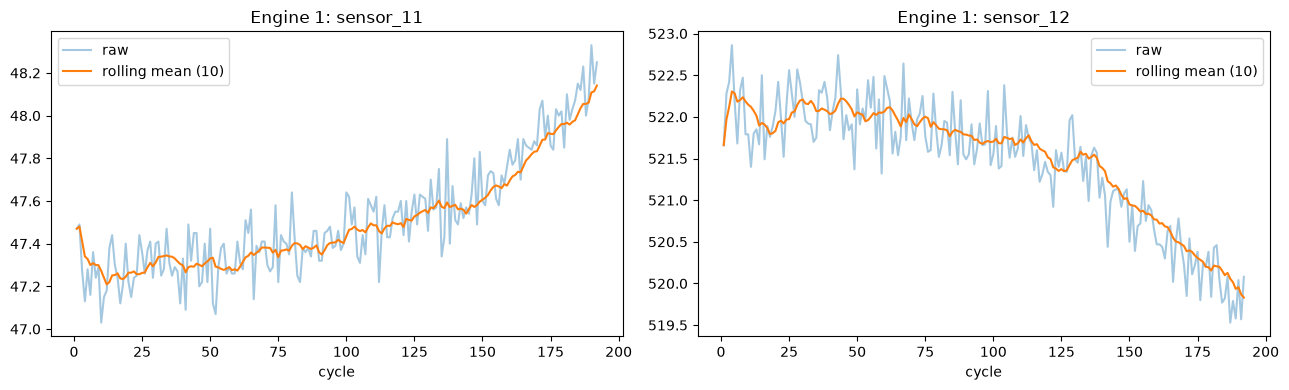

In [5]:
import matplotlib.pyplot as plt

d = feats[feats["unit"] == 1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, s in zip(axes, ["sensor_11", "sensor_12"]):
    ax.plot(d["cycle"], d[s], alpha=0.4, label="raw")
    ax.plot(d["cycle"], d[f"{s}_mean10"], label="rolling mean (10)")
    ax.set_title(f"Engine 1: {s}")
    ax.set_xlabel("cycle")
    ax.legend()
plt.tight_layout()
plt.show()

In [7]:
def _slope(a):
    n = len(a)
    x = np.arange(n)
    xm = x.mean()
    return ((x - xm) * (a - a.mean())).sum() / ((x - xm) ** 2).sum()

def add_slope_features(df, sensors, window=20):
    """Least-squares slope over a trailing window, computed per engine."""
    df = df.sort_values(["unit", "cycle"]).copy()
    g = df.groupby("unit")[sensors]
    slope = g.rolling(window, min_periods=2).apply(_slope, raw=True)
    slope = slope.reset_index(level=0, drop=True).add_suffix(f"_slope{window}")
    return df.join(slope)

slopes = add_slope_features(train, feature_sensors, window=20)
slope_cols = [c for c in slopes.columns if c.endswith("_slope20")]
print(slopes.shape)
print("NaNs per slope column:", int(slopes[slope_cols[0]].isna().sum()))

# Leakage test: remove the future and recompute
trunc = add_slope_features(train[train["unit"] == 1].head(100), feature_sensors, window=20)
a = slopes[slopes["unit"] == 1].head(100)[slope_cols].to_numpy()
b = trunc[slope_cols].to_numpy()
print("Identical when the future is removed:", np.allclose(a, b, equal_nan=True))

(20631, 31)
NaNs per slope column: 100
Identical when the future is removed: True


In [8]:
slopes[slope_cols] = slopes[slope_cols].fillna(0.0)

base = add_rolling_features(train, feature_sensors, window=10)
base[std_cols] = base[std_cols].fillna(0.0)

engineered = base.join(slopes[slope_cols])
print("Shape:", engineered.shape)
print("Remaining NaNs:", int(engineered.isna().sum().sum()))

Shape: (20631, 59)
Remaining NaNs: 0


In [9]:
train_ids = config["train_engine_ids"]
rows = []
for w in [5, 10, 20]:
    f = add_rolling_features(train, feature_sensors, window=w)
    f = f[f["unit"].isin(train_ids)]
    for s in feature_sensors:
        rows.append({"window": w, "sensor": s,
                     "abs_corr_with_RUL": abs(f[f"{s}_mean{w}"].corr(f["RUL"]))})
raw = train[train["unit"].isin(train_ids)]
for s in feature_sensors:
    rows.append({"window": 0, "sensor": s, "abs_corr_with_RUL": abs(raw[s].corr(raw["RUL"]))})

cmp = pd.DataFrame(rows).pivot(index="sensor", columns="window", values="abs_corr_with_RUL")
cmp.columns = ["raw", "w5", "w10", "w20"]
print(cmp.round(3))
print("\nMean abs correlation:\n", cmp.mean().round(3))

             raw     w5    w10    w20
sensor                               
sensor_11  0.684  0.720  0.716  0.698
sensor_12  0.658  0.698  0.695  0.677
sensor_13  0.548  0.582  0.575  0.553
sensor_14  0.308  0.310  0.307  0.301
sensor_15  0.631  0.710  0.714  0.700
sensor_17  0.596  0.704  0.715  0.707
sensor_2   0.597  0.702  0.712  0.702
sensor_20  0.619  0.705  0.710  0.697
sensor_21  0.624  0.713  0.718  0.707
sensor_3   0.575  0.700  0.715  0.710
sensor_4   0.666  0.719  0.719  0.704
sensor_7   0.645  0.699  0.698  0.682
sensor_8   0.551  0.586  0.579  0.557
sensor_9   0.387  0.391  0.390  0.385

Mean abs correlation:
 raw    0.578
w5     0.638
w10    0.640
w20    0.627
dtype: float64


In [10]:
engineered.to_csv(PROC_DIR / "train_engineered.csv", index=False)

config["engineered_features"] = {
    "rolling_window": 10,
    "slope_window": 20,
    "feature_groups": ["raw sensors", "rolling mean", "rolling std", "rolling slope"],
    "nan_fill": "0.0 for std and slope at cycle 1 only (verified)",
}
with open(PROC_DIR / "preprocessing_config.json", "w") as f:
    json.dump(config, f, indent=2)

print(sorted(p.name for p in PROC_DIR.glob("*")))
print(engineered.shape)

['preprocessing_config.json', 'train_engineered.csv', 'train_with_rul.csv']
(20631, 59)
